# TP Final · Opción B · 01 · Exploración, limpieza y variables

**Problema:** predecir cuántos minutos tarda una entrega (`Delivery_Time`) a partir de datos conocidos al momento del pedido: repartidor, ubicación, clima, tráfico, vehículo y hora. Es un problema de **regresión**.

**Datos:** *Amazon Delivery Dataset* (Kaggle), 43.739 entregas en India entre el 11/02/2022 y el 06/04/2022. Se eligió porque es un único archivo, tiene una variable objetivo numérica clara, mezcla variables numéricas y categóricas, y trae problemas de calidad reales para limpiar. Está relacionado con logística y cadena de suministro.

Este notebook: carga los datos, los explora, los limpia, construye variables, hace la partición temporal y guarda la tabla `delivery_features` para los notebooks siguientes.

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUTA = "/Volumes/workspace/tp_final_mbp/datos/amazon_delivery.csv"  
TABLA = "workspace.tp_final_belu.delivery_features"

raw = pd.read_csv(RUTA)
print(f"Filas: {len(raw):,} · Columnas: {raw.shape[1]}")
raw.head()

Filas: 43,739 · Columnas: 16


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


## 1. Primer vistazo

In [0]:
print(raw.dtypes)
print()
print("Nulos por columna (sólo las que tienen):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nOrder_ID duplicados:", raw["Order_ID"].duplicated().sum())
raw.describe().round(2).T

Order_ID            object
Agent_Age            int64
Agent_Rating       float64
Store_Latitude     float64
Store_Longitude    float64
Drop_Latitude      float64
Drop_Longitude     float64
Order_Date          object
Order_Time          object
Pickup_Time         object
Weather             object
Traffic             object
Vehicle             object
Area                object
Delivery_Time        int64
Category            object
dtype: object

Nulos por columna (sólo las que tienen):
Agent_Rating    54
Weather         91
dtype: int64

Order_ID duplicados: 0


,count,mean,std,min,25%,50%,75%,max
Agent_Age,43739.0,29.57,5.82,15.00,25.00,30.00,35.00,50.00
Agent_Rating,43685.0,4.63,0.33,1.00,4.50,4.70,4.90,6.00
Store_Latitude,43739.0,17.21,7.76,-30.90,12.93,18.55,22.73,30.91
Store_Longitude,43739.0,70.66,21.48,-88.37,73.17,75.90,78.05,88.43
Drop_Latitude,43739.0,17.46,7.34,0.01,12.99,18.63,22.79,31.05
Drop_Longitude,43739.0,70.82,21.15,0.01,73.28,76.00,78.10,88.56
Delivery_Time,43739.0,124.91,51.92,10.00,90.00,125.00,160.00,270.00


## 2. La variable objetivo

count    43739.0
mean       124.9
std         51.9
min         10.0
25%         90.0
50%        125.0
75%        160.0
max        270.0
Name: Delivery_Time, dtype: float64


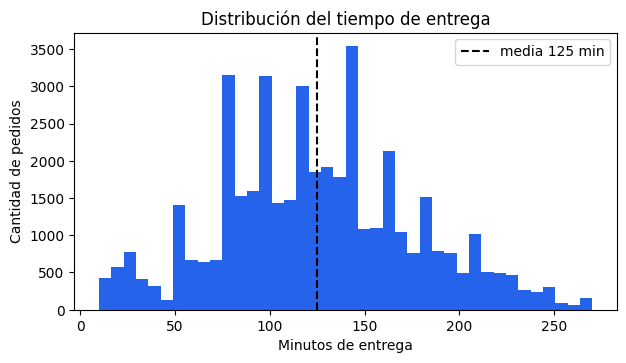

In [0]:
y = raw["Delivery_Time"]
print(y.describe().round(1))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(y, bins=40, color="#2563eb")
ax.axvline(y.mean(), color="black", ls="--", label=f"media {y.mean():.0f} min")
ax.set_xlabel("Minutos de entrega")
ax.set_ylabel("Cantidad de pedidos")
ax.set_title("Distribución del tiempo de entrega")
ax.legend()
plt.show()

## 3. Problemas de calidad detectados

Antes de limpiar, se cuenta cada problema para poder documentarlo.

In [0]:
cats = ["Weather", "Traffic", "Vehicle", "Area", "Category"]
problemas = {
    "Texto con espacios al final (Traffic, Vehicle, Area)": int(sum(raw[c].astype(str).ne(raw[c].astype(str).str.strip()).sum() for c in ["Traffic", "Vehicle", "Area"])),
    "Área escrita 'Metropolitian'": int(raw["Area"].str.strip().eq("Metropolitian").sum()),
    "Tráfico 'NaN' como texto": int(raw["Traffic"].str.strip().eq("NaN").sum()),
    "Clima faltante": int(raw["Weather"].isna().sum()),
    "Calificación del repartidor faltante": int(raw["Agent_Rating"].isna().sum()),
    "Calificación mayor a 5": int((raw["Agent_Rating"] > 5).sum()),
    "Repartidores menores de 18 años": int((raw["Agent_Age"] < 18).sum()),
    "Tiendas con coordenadas (0, 0)": int(((raw["Store_Latitude"] == 0) & (raw["Store_Longitude"] == 0)).sum()),
    "Tiendas con latitud o longitud negativa": int(((raw["Store_Latitude"] < 0) | (raw["Store_Longitude"] < 0)).sum()),
    "Hora del pedido faltante o mal formada": int((raw["Order_Time"].astype(str).str.len() != 8).sum()),
}
pd.DataFrame({"filas afectadas": problemas})

,filas afectadas
"Texto con espacios al final (Traffic, Vehicle, Area)",126521
Área escrita 'Metropolitian',32698
Tráfico 'NaN' como texto,91
Clima faltante,91
Calificación del repartidor faltante,54
Calificación mayor a 5,53
Repartidores menores de 18 años,38
"Tiendas con coordenadas (0, 0)",3505
Tiendas con latitud o longitud negativa,188
Hora del pedido faltante o mal formada,91


## 4. Limpieza

Decisiones:
- **Texto:** se eliminan los espacios, se corrige `Metropolitian` y `'NaN'` pasa a nulo real.
- **Calificación mayor a 5 y edad menor a 18:** son valores imposibles, se pasan a nulo (se imputan luego, dentro del pipeline de cada modelo, para no usar información del conjunto de test).
- **Coordenadas negativas:** las tiendas están en India (latitud y longitud positivas), así que se toma el valor absoluto.
- **Coordenadas (0, 0):** no se pueden corregir; la distancia queda nula y se agrega la marca `coords_invalidas`.
- No se eliminan filas: los problemas afectan a pocas filas y así no se pierde información.

In [0]:
df = raw.copy()

for c in ["Weather", "Traffic", "Vehicle", "Area", "Category"]:
    df[c] = df[c].astype("string").str.strip()
df["Area"] = df["Area"].replace({"Metropolitian": "Metropolitan"})
df["Traffic"] = df["Traffic"].replace({"NaN": pd.NA})

df.loc[df["Agent_Rating"] > 5, "Agent_Rating"] = np.nan
df.loc[df["Agent_Age"] < 18, "Agent_Age"] = np.nan

df["coords_invalidas"] = ((df["Store_Latitude"] == 0) & (df["Store_Longitude"] == 0)).astype(int)
for c in ["Store_Latitude", "Store_Longitude"]:
    df[c] = df[c].abs()
df.loc[df["coords_invalidas"] == 1, ["Store_Latitude", "Store_Longitude"]] = np.nan

print("Categorías después de limpiar:")
for c in ["Weather", "Traffic", "Vehicle", "Area"]:
    print(f"  {c}: {df[c].value_counts(dropna=False).to_dict()}")

Categorías después de limpiar:
  Weather: {'Fog': 7440, 'Stormy': 7374, 'Cloudy': 7288, 'Sandstorms': 7245, 'Windy': 7223, 'Sunny': 7078, <NA>: 91}
  Traffic: {'Low': 14999, 'Jam': 13725, 'Medium': 10628, 'High': 4296, <NA>: 91}
  Vehicle: {'motorcycle': 25527, 'scooter': 14639, 'van': 3558, 'bicycle': 15}
  Area: {'Metropolitan': 32698, 'Urban': 9751, 'Other': 1138, 'Semi-Urban': 152}


## 5. Variables nuevas

- `distancia_km`: distancia en línea recta entre la tienda y el destino (fórmula de Haversine).
- `hora_pedido` y `dia_semana`: momento del pedido.
- `demora_recogida_min`: minutos entre el pedido y la recogida. Algunos pedidos cruzan la medianoche, así que si da negativo se suman 24 horas.

In [0]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distancia_km"] = haversine_km(df["Store_Latitude"], df["Store_Longitude"], df["Drop_Latitude"], df["Drop_Longitude"])

df["order_date"] = pd.to_datetime(df["Order_Date"], format="%Y-%m-%d")
t_pedido = pd.to_datetime(df["Order_Time"], format="%H:%M:%S", errors="coerce")
t_recogida = pd.to_datetime(df["Pickup_Time"], format="%H:%M:%S", errors="coerce")
df["hora_pedido"] = t_pedido.dt.hour
df["dia_semana"] = df["order_date"].dt.dayofweek
demora = (t_recogida - t_pedido).dt.total_seconds() / 60
df["demora_recogida_min"] = np.where(demora < 0, demora + 1440, demora)

df[["distancia_km", "hora_pedido", "dia_semana", "demora_recogida_min"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
distancia_km,40234.0,9.72,5.60,1.47,4.66,9.19,13.63,20.97
hora_pedido,43648.0,17.43,4.82,0.00,15.00,19.00,21.00,23.00
dia_semana,43739.0,3.00,1.97,0.00,1.00,3.00,5.00,6.00
demora_recogida_min,43648.0,9.99,4.09,5.00,5.00,10.00,15.00,15.00


## 6. Qué se relaciona con el tiempo de entrega

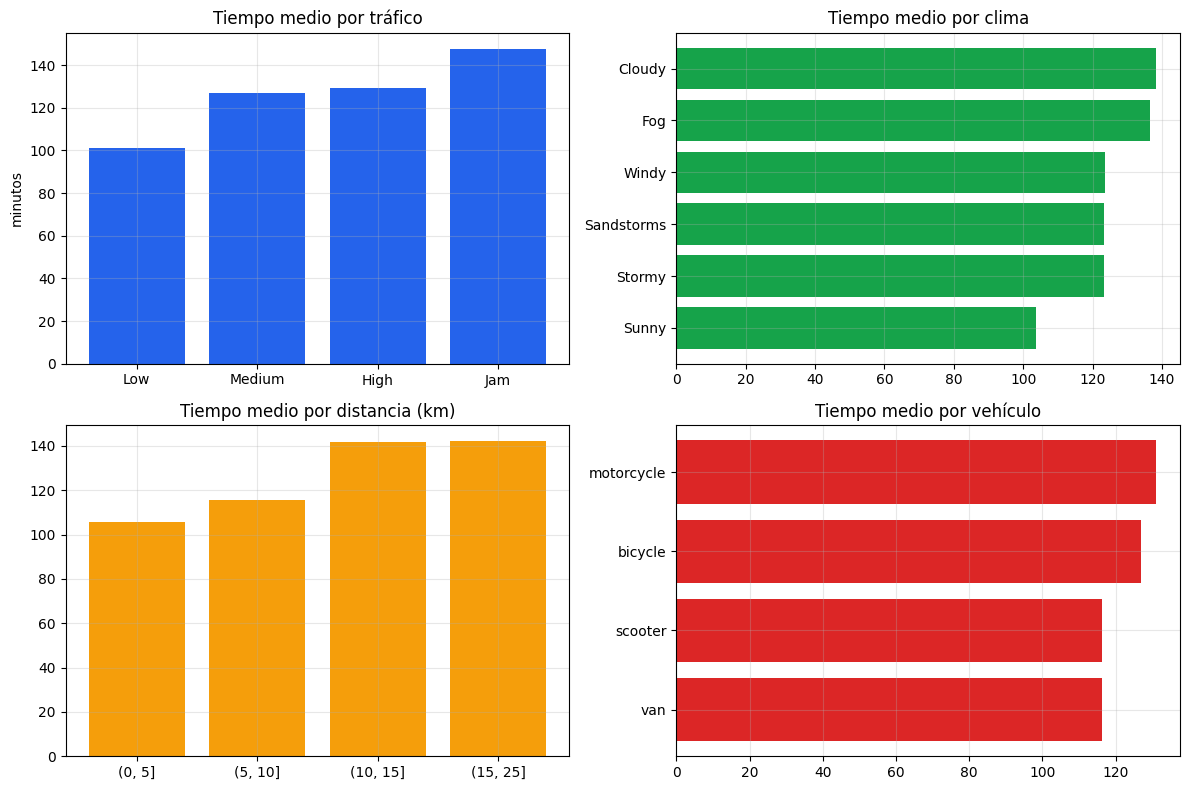

In [0]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

orden_traf = ["Low", "Medium", "High", "Jam"]
g = df.groupby("Traffic")["Delivery_Time"].mean().reindex(orden_traf)
axes[0, 0].bar(g.index, g.values, color="#2563eb")
axes[0, 0].set_title("Tiempo medio por tráfico")
axes[0, 0].set_ylabel("minutos")

g = df.groupby("Weather")["Delivery_Time"].mean().sort_values()
axes[0, 1].barh(g.index, g.values, color="#16a34a")
axes[0, 1].set_title("Tiempo medio por clima")

bins = pd.cut(df["distancia_km"], bins=[0, 5, 10, 15, 25])
g = df.groupby(bins, observed=True)["Delivery_Time"].mean()
axes[1, 0].bar([str(i) for i in g.index], g.values, color="#f59e0b")
axes[1, 0].set_title("Tiempo medio por distancia (km)")

g = df.groupby("Vehicle")["Delivery_Time"].mean().sort_values()
axes[1, 1].barh(g.index, g.values, color="#dc2626")
axes[1, 1].set_title("Tiempo medio por vehículo")

for ax in axes.ravel():
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [0]:
num = ["distancia_km", "demora_recogida_min", "hora_pedido", "dia_semana", "Agent_Age", "Agent_Rating"]
corr = df[num + ["Delivery_Time"]].corr()["Delivery_Time"].drop("Delivery_Time").round(3)
print("Correlación de cada variable numérica con Delivery_Time:")
print(corr.sort_values(key=abs, ascending=False))

Correlación de cada variable numérica con Delivery_Time:
Agent_Rating          -0.292
distancia_km           0.278
Agent_Age              0.256
hora_pedido            0.159
demora_recogida_min   -0.009
dia_semana             0.006
Name: Delivery_Time, dtype: float64


## 7. Partición temporal y tabla final

Como en un caso real, se **entrena con el pasado y se evalúa con lo que viene después**: los pedidos hasta el 29/03/2022 son `train` (≈ 81 %) y los posteriores son `test`. La partición es la misma para todos los modelos, así la comparación es justa.

Se descartan `Order_ID`, las coordenadas crudas y las columnas de texto de fecha y hora (ya están representadas en las variables nuevas).

In [0]:
CORTE = pd.Timestamp("2022-03-29")
df["split"] = np.where(df["order_date"] <= CORTE, "train", "test")

cols = ["Order_ID", "order_date", "split", "Delivery_Time",
        "Agent_Age", "Agent_Rating", "distancia_km", "coords_invalidas",
        "hora_pedido", "dia_semana", "demora_recogida_min",
        "Weather", "Traffic", "Vehicle", "Area", "Category"]
final = df[cols].copy()
for c in ["Weather", "Traffic", "Vehicle", "Area", "Category"]:
    final[c] = final[c].astype(object).where(final[c].notna(), None)

print(final.groupby("split")["Delivery_Time"].agg(filas="count", media="mean").round(1))
print("\nNulos en la tabla final:")
print(final.isna().sum()[final.isna().sum() > 0])

       filas  media
split              
test    8119  124.1
train  35620  125.1

Nulos en la tabla final:
Agent_Age                38
Agent_Rating            107
distancia_km           3505
hora_pedido              91
demora_recogida_min      91
Weather                  91
Traffic                  91
dtype: int64


In [0]:
spark.sql("CREATE SCHEMA IF NOT EXISTS workspace.tp_final_belu")

DataFrame[]

In [0]:
spark.createDataFrame(final).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(TABLA)
print("Guardada:", TABLA, "·", spark.table(TABLA).count(), "filas")

Guardada: workspace.tp_final_belu.delivery_features · 43739 filas


## Resumen

- Problema de regresión: predecir `Delivery_Time` en minutos con datos conocidos al hacer el pedido.
- Se corrigieron textos, valores imposibles y coordenadas inválidas sin eliminar filas; la imputación de nulos se hace dentro del pipeline de cada modelo.
- Variables nuevas: distancia (Haversine), hora, día de la semana y demora de recogida.
- Partición temporal: `train` hasta el 29/03/2022 y `test` después.
- Limitación: 3.505 pedidos (≈ 8 %) no tienen distancia por coordenadas inválidas en la tienda.